# Inside Decision Tree Regression: Build, See, and Experiment
### A coached companion to `DecisionTreeRegression_Workshop`

**Learning targets.** By the end, explain a regression tree's yes/no questions, calculate candidate squared-error splits, build a small CART-style regression tree in plain Python, interpret the staircase prediction, and extend the intuition to classification. Then experiment with the same `max_depth` settings used in the main workshop.

**Learning route:** predict → calculate → implement → inspect → experiment → transfer to classification → reflect.

> Using scikit-learn allows you to train decision trees and generate predictions, but understanding how the algorithm works is essential. **This coaching notebook takes you behind the scenes** to explore splitting decisions, error calculations, tree construction, and hyperparameters, helping you interpret results, troubleshoot models, and make informed machine learning decisions independently.

**Source mapping:** This notebook adapts the Ontario time-of-use electricity example in the accompanying `ParametricNon-Parametric_Regression_Lab.html` (the Decision Tree tab at `#family`, the use case `t1`, and the split-loss exploration). The rate tiers here are **synthetic educational values**, not a statement of current Ontario electricity rates. The visual explanatory progression is original but inspired by [StatQuest: Regression Trees, Clearly Explained](https://youtu.be/g9c66TUylZ4). The classification extension reuses the 20 observations in [Wikipedia's logistic-regression example](https://en.wikipedia.org/wiki/Logistic_regression#Example). The main workshop applies regression to California Housing and classification to Iris: [DecisionTreeRegression_Workshop](https://github.com/ProfEspinosaAIML/DecisionTreeRegression_Workshop).

## 0 · Set up our classroom lab

> **Use in VS Code:** Open this `.ipynb`, choose a Python kernel, and run cells from top to bottom. Required packages: `numpy`, `pandas`, `matplotlib`, `scikit-learn`. If necessary run `python -m pip install numpy pandas matplotlib scikit-learn ipykernel` in your environment's terminal.
>
> No internet access or other files are needed to execute this notebook. All graphics are generated as Matplotlib figures.

**Coach's question:** If the price of electricity jumps at particular times, would a smooth straight line or a collection of *if/else* rules better describe it? Write your prediction before running the plot.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11})
print('Ready. NumPy:', np.__version__)

Ready. NumPy: 2.3.3


## 1 · The story: electricity price is a staircase

Our attached Regression Lab defines the illustrative hourly-rate function:

- **Off-peak:** before 07:00 or at/after 19:00 → **7.6 ¢/kWh**
- **Mid-peak:** 07:00–11:00 and 17:00–19:00 → **12.2 ¢/kWh**
- **On-peak:** 11:00–17:00 → **15.8 ¢/kWh**

The lab also adds random noise to its synthetic measured observations. We use the *same underlying function* here, with NumPy-generated noise. An individual random sample will not match the browser app's random-number generator.

A **regression tree** predicts a number. At each internal node, it asks an inequality such as `hour <= 11.2`. At each **leaf**, it predicts the **mean observed target** of training records reaching that leaf. In one feature, this produces horizontal steps—not a sloping line.

**Predict before running:** Where might the first split be? Why might the answer depend on how many observations fall in each price tier?

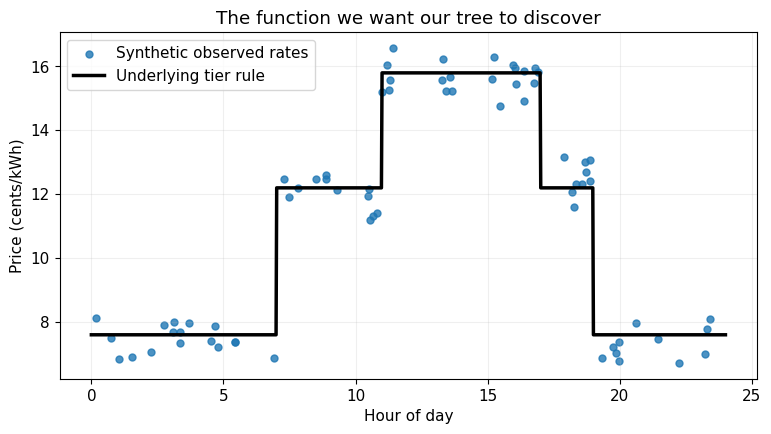

In [3]:
def electricity_rate(hour):
    hour = np.asarray(hour)
    return np.where((hour < 7) | (hour >= 19), 7.6,
                    np.where((hour >= 11) & (hour < 17), 15.8, 12.2))

rng = np.random.default_rng(RANDOM_STATE)
hours = np.sort(rng.uniform(0, 24, 70))
prices = electricity_rate(hours) + rng.normal(0, 0.6, len(hours))
xx = np.linspace(0, 24, 1000)
fig, ax = plt.subplots()
ax.scatter(hours, prices, s=25, alpha=.8, label='Synthetic observed rates')
ax.plot(xx, electricity_rate(xx), color='black', lw=2.5, label='Underlying tier rule')
ax.set(xlabel='Hour of day', ylabel='Price (cents/kWh)', title='The function we want our tree to discover')
ax.legend(); ax.grid(alpha=.2); plt.show()

## 2 · Before training: learn the meaning of one split

We begin with just **six illustrative readings**, chosen for arithmetic clarity. This mini-dataset is a teaching example; the larger synthetic electricity dataset above is used later.

A threshold partitions the data into a left group (`hour <= threshold`) and a right group (`hour > threshold`). In each group, the best constant prediction under squared error is its **mean**.

Given target values \(y_i\), the total **sum of squared errors** at a candidate threshold \(t\) is

$$
\mathrm{SSE}(t)=\sum_{i:x_i\leq t}(y_i-\bar{y}_L)^2+\sum_{i:x_i>t}(y_i-\bar{y}_R)^2.
$$

A split is chosen to **minimize SSE**, equivalently the weighted average of the two child MSEs. Scikit-learn's `criterion="squared_error"` uses variance/squared-error reduction. A *simple average of left and right MSEs without sample weights* would be incorrect for uneven group sizes.

**Try it first:** For observations `(hour, price)` = `(2,8), (5,8), (9,12), (12,16), (15,16), (21,8)`, what would happen if we split at 10.5? Which observation belongs on each side?

In [4]:
toy_hour = np.array([2., 5., 9., 12., 15., 21.])
toy_price = np.array([8., 8., 12., 16., 16., 8.])
toy = pd.DataFrame({'hour': toy_hour, 'price': toy_price})
display(toy)

def score_split(x, y, threshold):
    left = x <= threshold
    right = ~left
    if not left.any() or not right.any():
        return None
    mean_left, mean_right = y[left].mean(), y[right].mean()
    sse_left = np.sum((y[left] - mean_left)**2)
    sse_right = np.sum((y[right] - mean_right)**2)
    return {'threshold': float(threshold), 'n_left': int(left.sum()),
            'n_right': int(right.sum()), 'mean_left': mean_left,
            'mean_right': mean_right, 'sse_left': sse_left,
            'sse_right': sse_right, 'total_sse': sse_left + sse_right}

# Step through one complete candidate split using Python as the calculator.
t = 10.5
result = score_split(toy_hour, toy_price, t)
print('Left observations:', toy_price[toy_hour <= t].tolist())
print('Right observations:', toy_price[toy_hour > t].tolist())
for name, value in result.items(): print(f'{name:>12}: {value:.3f}')
assert np.isclose(result['total_sse'], 160.0/3), 'Check the arithmetic.'

,hour,price
0,2.0,8.0
1,5.0,8.0
2,9.0,12.0
3,12.0,16.0
4,15.0,16.0
5,21.0,8.0


Left observations: [8.0, 8.0, 12.0]
Right observations: [16.0, 16.0, 8.0]
   threshold: 10.500
      n_left: 3.000
     n_right: 3.000
   mean_left: 9.333
  mean_right: 13.333
    sse_left: 10.667
   sse_right: 42.667
   total_sse: 53.333


### Draw the residuals

The horizontal lines show what each side would predict. Each vertical segment is a residual: `actual - predicted`. Squaring and adding those residuals gives our score for this split.

**Think:** Would an unequal split (five points on one side, one on the other) be scored fairly if we merely averaged the two group MSEs without weighting?

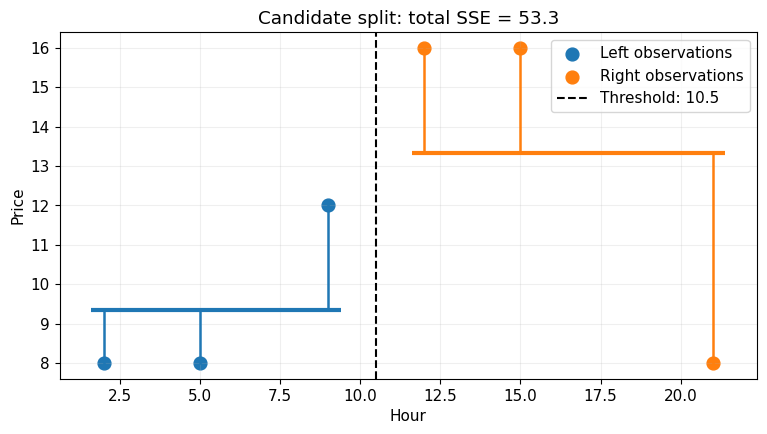

In [5]:
fig, ax = plt.subplots()
mask = toy_hour <= t
ax.scatter(toy_hour[mask], toy_price[mask], s=85, label='Left observations')
ax.scatter(toy_hour[~mask], toy_price[~mask], s=85, label='Right observations')
ax.axvline(t, color='black', ls='--', label=f'Threshold: {t:g}')
for part, mu, color in [(mask, result['mean_left'], 'C0'), (~mask, result['mean_right'], 'C1')]:
    ax.hlines(mu, toy_hour[part].min()-.4, toy_hour[part].max()+.4, colors=color, lw=3)
    for h, p in zip(toy_hour[part], toy_price[part]):
        ax.plot([h,h], [p,mu], color=color, lw=1.8)
ax.set(xlabel='Hour', ylabel='Price', title=f'Candidate split: total SSE = {result["total_sse"]:.1f}')
ax.legend(); ax.grid(alpha=.2); plt.show()

## 3 · Try every candidate threshold (the CART idea)

A tree does not guess one threshold. For one numeric feature it sorts the **distinct** feature values and evaluates midpoints between consecutive values. Candidate midpoints generate every possible distinct left/right partition for this toy dataset. The tree chooses the smallest child SSE; it doesn't use gradient descent.

**Predict first:** Will `10.5` be the best split? Compare it against the other possible midpoints before running.

,threshold,n_left,n_right,mean_left,mean_right,sse_left,sse_right,total_sse
0,3.5,1,5,8.000,12.000,0.000,64.000,64.000
1,7.0,2,4,8.000,13.000,0.000,44.000,44.000
2,10.5,3,3,9.333,13.333,10.667,42.667,53.333
3,13.5,4,2,11.000,12.000,44.000,32.000,76.000
4,18.0,5,1,12.000,8.000,64.000,0.000,64.000


Best split: hour <= 7; total SSE = 44.000


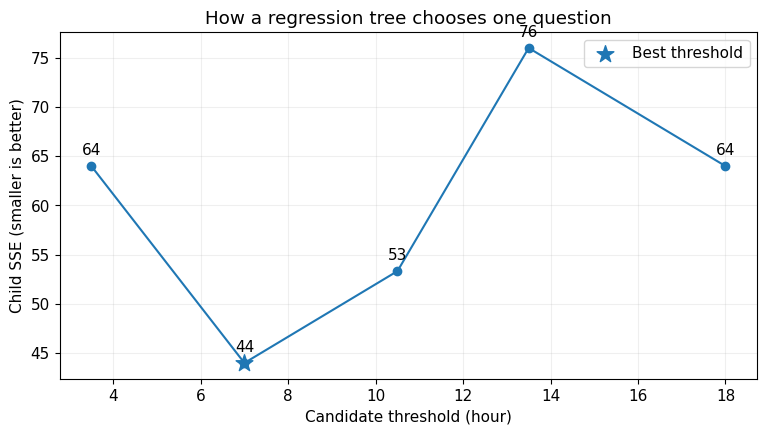

In [6]:
def candidate_thresholds(x):
    unique = np.unique(np.asarray(x, dtype=float))
    return (unique[:-1] + unique[1:]) / 2

search = pd.DataFrame([score_split(toy_hour, toy_price, threshold)
                       for threshold in candidate_thresholds(toy_hour)])
display(search.round(3))
best = search.loc[search.total_sse.idxmin()]
print(f'Best split: hour <= {best.threshold:g}; total SSE = {best.total_sse:.3f}')

fig, ax = plt.subplots()
ax.plot(search.threshold, search.total_sse, '-o')
ax.scatter([best.threshold], [best.total_sse], s=160, marker='*', zorder=5, label='Best threshold')
for row in search.itertuples(): ax.annotate(f'{row.total_sse:.0f}', (row.threshold, row.total_sse), xytext=(0, 8), textcoords='offset points', ha='center')
ax.set(xlabel='Candidate threshold (hour)', ylabel='Child SSE (smaller is better)', title='How a regression tree chooses one question')
ax.legend(); ax.grid(alpha=.2); plt.show()

### An algorithm in plain language

1. Collect all observations currently at this node.
2. If we have reached a stopping rule (such as `max_depth`, too few samples, or no improvement), make a leaf predicting the target mean.
3. Otherwise, consider each feature and each useful threshold.
4. Compute the **left SSE + right SSE** for every eligible split.
5. Choose the lowest-error split and repeat on both children.
6. To predict for a new record, follow its yes/no answers until a leaf; return that leaf's mean.

This is a **greedy** recursive procedure: it makes the best immediate split but does not promise a globally optimal complete tree. The next code intentionally supports **one numeric feature only** and the squared-error criterion, so you can understand each line.

In [7]:
# Small CART-style regression tree, written from scratch (NO scikit-learn).
# Each node is an ordinary Python dictionary.
def build_regression_tree(x, y, max_depth=2, min_samples_leaf=1, depth=0):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    node = {'prediction': float(y.mean()), 'samples': len(y), 'depth': depth}
    parent_sse = float(np.sum((y - y.mean())**2))
    if depth >= max_depth or len(y) < 2 * min_samples_leaf or parent_sse < 1e-12:
        node['leaf'] = True
        return node
    choices = []
    for threshold in candidate_thresholds(x):
        left = x <= threshold
        if left.sum() < min_samples_leaf or (~left).sum() < min_samples_leaf:
            continue
        info = score_split(x, y, threshold)
        choices.append(info)
    if not choices:
        node['leaf'] = True
        return node
    best_choice = min(choices, key=lambda r: r['total_sse'])
    if best_choice['total_sse'] >= parent_sse - 1e-12:
        node['leaf'] = True
        return node
    t = best_choice['threshold']
    left = x <= t
    node.update(leaf=False, threshold=t, sse_after_split=best_choice['total_sse'],
                left=build_regression_tree(x[left], y[left], max_depth, min_samples_leaf, depth + 1),
                right=build_regression_tree(x[~left], y[~left], max_depth, min_samples_leaf, depth + 1))
    return node

def predict_one(tree, hour):
    node = tree
    while not node['leaf']:
        node = node['left'] if hour <= node['threshold'] else node['right']
    return node['prediction']

def predict_many(tree, x):
    return np.array([predict_one(tree, float(value)) for value in np.asarray(x).ravel()])

def print_rules(tree, indent=''):
    if tree['leaf']:
        print(f"{indent}LEAF: mean={tree['prediction']:.2f} (n={tree['samples']})")
    else:
        print(f"{indent}IF hour <= {tree['threshold']:.2f}:")
        print_rules(tree['left'], indent + '    ')
        print(f"{indent}ELSE:")
        print_rules(tree['right'], indent + '    ')

toy_tree = build_regression_tree(toy_hour, toy_price, max_depth=2)
print_rules(toy_tree)
for h in [4, 10, 14, 20]:
    print(f'At hour {h:2}, predicted price = {predict_one(toy_tree, h):.2f}')

IF hour <= 7.00:
    LEAF: mean=8.00 (n=2)
ELSE:
    IF hour <= 18.00:
        LEAF: mean=14.67 (n=3)
    ELSE:
        LEAF: mean=8.00 (n=1)
At hour  4, predicted price = 8.00
At hour 10, predicted price = 14.67
At hour 14, predicted price = 14.67
At hour 20, predicted price = 8.00


### Plot our homemade tree as a staircase

**Coach's question:** Which parts of the graph are horizontal, and why? Why is the prediction not necessarily one of the original observed prices?

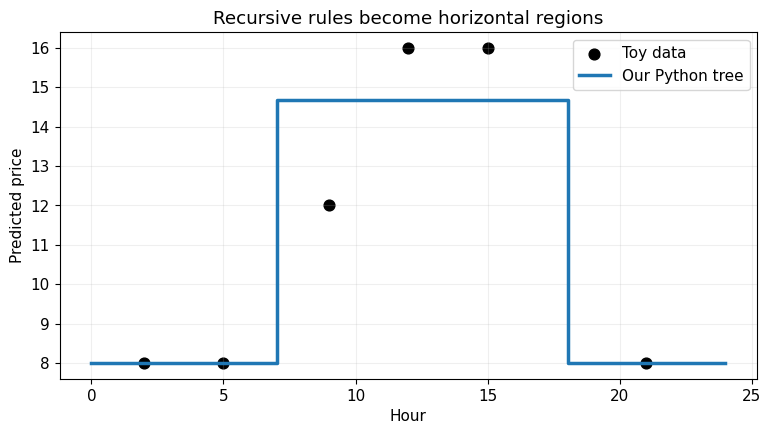

In [8]:
grid = np.linspace(0, 24, 500)
fig, ax = plt.subplots()
ax.scatter(toy_hour, toy_price, s=60, color='black', label='Toy data')
ax.step(grid, predict_many(toy_tree, grid), where='post', lw=2.5, label='Our Python tree')
ax.set(xlabel='Hour', ylabel='Predicted price', title='Recursive rules become horizontal regions')
ax.legend(); ax.grid(alpha=.2); plt.show()

## 4 · Verify against scikit-learn

The classroom algorithm uses the same basic greedy squared-error principle as CART. It is **not** an exact implementation of every scikit-learn optimization, stopping option, floating-point threshold convention, or tie-breaking rule. On this one-feature toy example, compare the resulting partitions and predictions.

**What to inspect:** the root threshold, number of leaves, and prediction for each training point.

,hour,actual,from_scratch,scikit_learn
0,2.0,8.0,8.000000,8.000000
1,5.0,8.0,8.000000,8.000000
2,9.0,12.0,14.666667,14.666667
3,12.0,16.0,14.666667,14.666667
4,15.0,16.0,14.666667,14.666667
5,21.0,8.0,8.000000,8.000000


|--- hour <= 7.00
|   |--- value: [8.00]
|--- hour >  7.00
|   |--- hour <= 18.00
|   |   |--- value: [14.67]
|   |--- hour >  18.00
|   |   |--- value: [8.00]



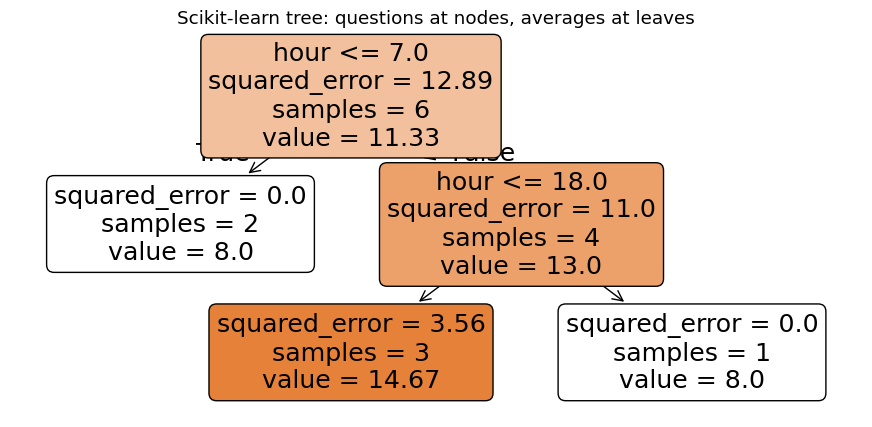

In [9]:
sk_toy = DecisionTreeRegressor(max_depth=2, random_state=42)
sk_toy.fit(toy_hour.reshape(-1, 1), toy_price)
comparison = pd.DataFrame({'hour': toy_hour, 'actual': toy_price,
                           'from_scratch': predict_many(toy_tree, toy_hour),
                           'scikit_learn': sk_toy.predict(toy_hour.reshape(-1, 1))})
display(comparison)
print(export_text(sk_toy, feature_names=['hour']))
fig, ax = plt.subplots(figsize=(11, 5))
plot_tree(sk_toy, feature_names=['hour'], filled=True, rounded=True, precision=2, ax=ax)
ax.set_title('Scikit-learn tree: questions at nodes, averages at leaves'); plt.show()

## 5 · Grow a tree on the attached lab's electricity scenario

Now return to the larger synthetic dataset constructed in Section 1. We first make a train/test split to avoid evaluating only on the observations we trained on. Here is the exact style used in your existing workshop:

```python
reg_tree = DecisionTreeRegressor(max_depth=6, random_state=42)
reg_tree.fit(X_train_c, y_train_c)
```

The variable names below are local to this **standalone supplement**, so it does not require any notebook variables from the main workshop. Try changing `REG_MAX_DEPTH` and `REG_MIN_SAMPLES_LEAF`; rerun the cell and explain each visible change.

Depth=6, leaves=32
Train MSE=0.031 | Test MSE=0.284


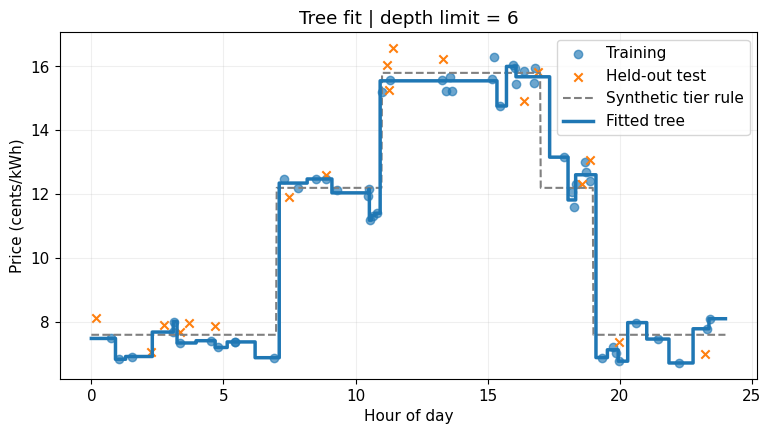

In [10]:
X = hours.reshape(-1, 1)
y = prices
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE)

# EXPERIMENT: Start with the workshop's depth, then try 1, 2, 3, 10.
REG_MAX_DEPTH = 6
REG_MIN_SAMPLES_LEAF = 1
REG_MIN_SAMPLES_SPLIT = 2
REG_CRITERION = 'squared_error'  # later try 'absolute_error'

reg_tree = DecisionTreeRegressor(max_depth=REG_MAX_DEPTH,
                                 min_samples_leaf=REG_MIN_SAMPLES_LEAF,
                                 min_samples_split=REG_MIN_SAMPLES_SPLIT,
                                 criterion=REG_CRITERION,
                                 random_state=42)
reg_tree.fit(X_train, y_train)
train_mse = mean_squared_error(y_train, reg_tree.predict(X_train))
test_mse = mean_squared_error(y_test, reg_tree.predict(X_test))
print(f'Depth={reg_tree.get_depth()}, leaves={reg_tree.get_n_leaves()}')
print(f'Train MSE={train_mse:.3f} | Test MSE={test_mse:.3f}')

fig, ax = plt.subplots()
ax.scatter(X_train.ravel(), y_train, alpha=.65, label='Training')
ax.scatter(X_test.ravel(), y_test, marker='x', label='Held-out test')
ax.plot(xx, electricity_rate(xx), ls='--', color='gray', label='Synthetic tier rule')
ax.step(xx, reg_tree.predict(xx.reshape(-1,1)), where='post', lw=2.5, label='Fitted tree')
ax.set(xlabel='Hour of day', ylabel='Price (cents/kWh)', title=f'Tree fit | depth limit = {REG_MAX_DEPTH}')
ax.legend(); ax.grid(alpha=.2); plt.show()

### Picture the decision structure

For legibility we display the first three levels of the possibly deeper tree. `plot_tree(..., max_depth=3)` limits **only the visualization**, not the model that was fitted. The full set of rules remains available through `export_text`.

In [ ]:
fig, ax = plt.subplots(figsize=(15, 7))
plot_tree(reg_tree, max_depth=3, feature_names=['hour'], filled=True,
          rounded=True, fontsize=9, ax=ax, precision=2)
ax.set_title('Top levels of our fitted regression tree'); plt.show()
print(export_text(reg_tree, feature_names=['hour'], max_depth=3))

## 6 · Hyperparameter laboratory (ordinary Python variables)

`max_depth` controls how many times rules may be nested, `min_samples_leaf` prevents leaves from having too few training records, and `min_samples_split` controls whether a node has enough observations to attempt a split. With `criterion="squared_error"`, leaf predictions minimize squared error and use the mean. `criterion="absolute_error"` uses a median-based leaf prediction and minimizes absolute error; it can be more resistant to outliers but may take longer.

**Before executing:** Would a depth-1 tree be biased or highly variable? Would a very deep tree necessarily improve **test** performance? Explain before reading the output.

This loop compares models using the *same holdout set*; do not select a final production model repeatedly using its test score. Hyperparameter selection normally belongs on a validation set or cross-validation folds.

,max_depth,min_samples_leaf,actual_depth,leaves,train_mse,test_mse
0,1,1,1,2,7.607,7.206
1,2,1,2,4,1.985,2.008
2,3,1,3,8,1.048,1.167
3,4,1,4,15,0.100,0.271
4,6,1,6,32,0.031,0.284
5,10,1,10,50,0.002,0.336
6,None,1,12,52,0.000,0.336
7,1,3,1,2,7.607,7.206
8,2,3,2,4,1.985,2.008
9,3,3,3,7,1.057,1.150


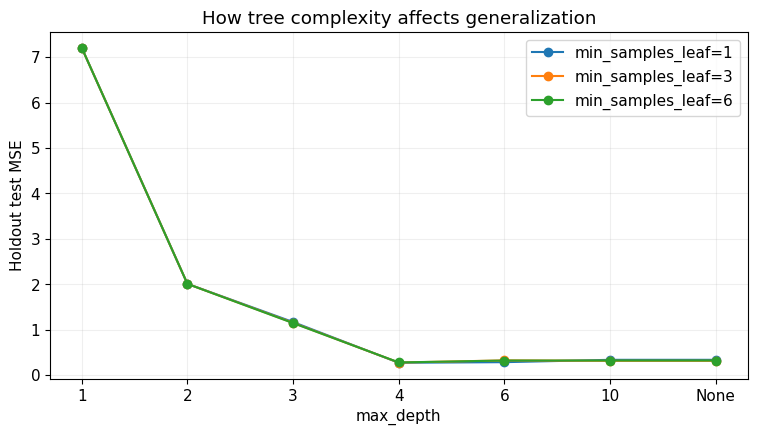

In [11]:
depth_choices = [1, 2, 3, 4, 6, 10, None]
leaf_choices = [1, 3, 6]
rows = []
for leaf_size in leaf_choices:
    for depth in depth_choices:
        model = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf_size,
                                      random_state=RANDOM_STATE)
        model.fit(X_train, y_train)
        rows.append({'max_depth': str(depth), 'min_samples_leaf': leaf_size,
                     'actual_depth': model.get_depth(), 'leaves': model.get_n_leaves(),
                     'train_mse': mean_squared_error(y_train, model.predict(X_train)),
                     'test_mse': mean_squared_error(y_test, model.predict(X_test))})
results = pd.DataFrame(rows)
display(results.round(3))
fig, ax = plt.subplots()
for leaf_size in leaf_choices:
    section = results[results.min_samples_leaf == leaf_size]
    ax.plot(range(len(depth_choices)), section.test_mse, '-o', label=f'min_samples_leaf={leaf_size}')
ax.set_xticks(range(len(depth_choices)), [str(v) for v in depth_choices])
ax.set(xlabel='max_depth', ylabel='Holdout test MSE', title='How tree complexity affects generalization')
ax.legend(); ax.grid(alpha=.2); plt.show()

### A second experiment: see a large noise point change the fitted tree

Modify `criterion_choice` and keep everything else the same. `squared_error` targets the mean; `absolute_error` targets the median. This comparison deliberately adds one extreme value to **training only**. That is a diagnostic experiment, not a recommendation to modify datasets indiscriminately.

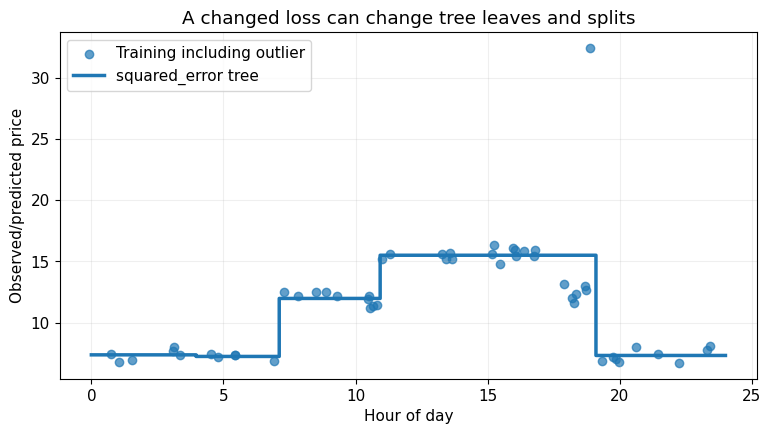

In [12]:
X_with_outlier = X_train.copy()
y_with_outlier = y_train.copy()
y_with_outlier[0] += 20

criterion_choice = 'squared_error'   # CHANGE to 'absolute_error'
robust_tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=5,
                                    criterion=criterion_choice, random_state=42)
robust_tree.fit(X_with_outlier, y_with_outlier)
fig, ax = plt.subplots()
ax.scatter(X_with_outlier.ravel(), y_with_outlier, alpha=.7, label='Training including outlier')
ax.step(xx, robust_tree.predict(xx.reshape(-1, 1)), where='post', lw=2.5,
        label=f'{criterion_choice} tree')
ax.set(xlabel='Hour of day', ylabel='Observed/predicted price', title='A changed loss can change tree leaves and splits')
ax.legend(); ax.grid(alpha=.2); plt.show()

## 7 · Classification is a related tree with a different goal

A regression leaf predicts a **number** (typically a mean under squared error). A classification leaf predicts a **category** (the most frequent training label at that leaf), and the tree can also estimate class probabilities from class proportions at that leaf.

For the default `DecisionTreeClassifier(criterion="gini")`, the impurity of a node is

\[
G = 1-\sum_{k=1}^{K}p_k^2.
\]

A candidate split minimizes the **sample-count-weighted Gini impurity** of the children. A perfectly single-class leaf has Gini = 0. Contrast this with the numeric SSE objective used earlier.

**The second teaching dataset** is the 20-student Wikipedia example: *hours studied* and whether the student *passed* (`1`) or *failed* (`0`). Here logistic regression predicts a smooth probability through a parametric sigmoid, while the tree predicts piecewise-constant class probabilities and labels. Both are **classifiers** despite logistic regression's name.

,hours_studied,passed
0,0.50,0
1,0.75,0
2,1.00,0
3,1.25,0
4,1.50,0
5,1.75,0
6,1.75,1
7,2.00,0
8,2.25,1
9,2.50,0


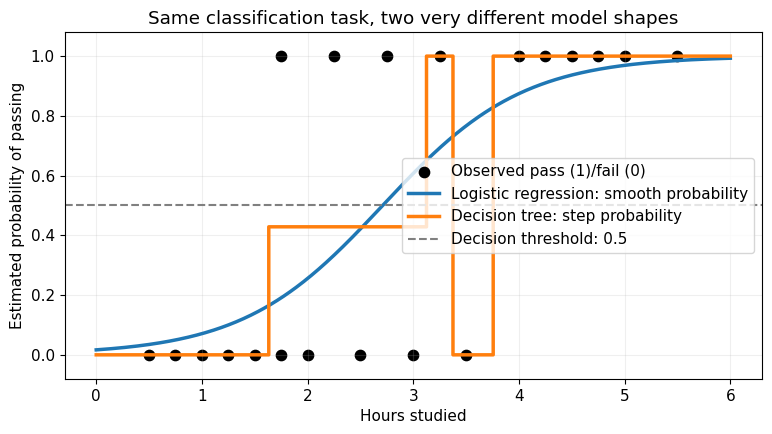

Logistic predicted class: [0, 1]
Tree predicted class: [0, 1]
Tree decision rules:
|--- hours_studied <= 3.75
|   |--- hours_studied <= 1.62
|   |   |--- class: 0
|   |--- hours_studied >  1.62
|   |   |--- hours_studied <= 3.38
|   |   |   |--- hours_studied <= 3.12
|   |   |   |   |--- class: 0
|   |   |   |--- hours_studied >  3.12
|   |   |   |   |--- class: 1
|   |   |--- hours_studied >  3.38
|   |   |   |--- class: 0
|--- hours_studied >  3.75
|   |--- class: 1



In [13]:
# The 20 data pairs from Wikipedia's logistic regression example.
study_hours = np.array([.50,.75,1.00,1.25,1.50,1.75,1.75,2.00,2.25,2.50,
                        2.75,3.00,3.25,3.50,4.00,4.25,4.50,4.75,5.00,5.50])
passed = np.array([0,0,0,0,0,0,1,0,1,0,1,0,1,0,1,1,1,1,1,1])
student_data = pd.DataFrame({'hours_studied': study_hours, 'passed': passed})
display(student_data)

# The main workshop uses: DecisionTreeClassifier(max_depth=4, random_state=42)
CLF_MAX_DEPTH = 4  # Try 1, 2, 4, and None.
CLF_MIN_SAMPLES_LEAF = 1 # Try 2, then 4.
CLF_CRITERION = 'gini' # Also try 'entropy'.

clf_tree = DecisionTreeClassifier(max_depth=CLF_MAX_DEPTH,
                                  min_samples_leaf=CLF_MIN_SAMPLES_LEAF,
                                  criterion=CLF_CRITERION, random_state=42)
clf_tree.fit(study_hours.reshape(-1, 1), passed)
logit = LogisticRegression(C=1e6, max_iter=1000)
logit.fit(study_hours.reshape(-1, 1), passed)

x_plot = np.linspace(0, 6, 600).reshape(-1, 1)
p_tree = clf_tree.predict_proba(x_plot)[:, 1]
p_logit = logit.predict_proba(x_plot)[:, 1]
fig, ax = plt.subplots()
ax.scatter(study_hours, passed, color='black', s=55, label='Observed pass (1)/fail (0)')
ax.plot(x_plot.ravel(), p_logit, lw=2.5, label='Logistic regression: smooth probability')
ax.step(x_plot.ravel(), p_tree, where='post', lw=2.5, label='Decision tree: step probability')
ax.axhline(.5, color='gray', ls='--', label='Decision threshold: 0.5')
ax.set(xlabel='Hours studied', ylabel='Estimated probability of passing', ylim=(-.08,1.08),
       title='Same classification task, two very different model shapes')
ax.legend(loc='center right'); ax.grid(alpha=.2); plt.show()
print('Logistic predicted class:', logit.predict([[2], [4]]).tolist())
print('Tree predicted class:', clf_tree.predict([[2], [4]]).tolist())
print('Tree decision rules:\n' + export_text(clf_tree, feature_names=['hours_studied']))

### Compare **decision boundaries** with **probability shapes**

On one feature, the classification boundary is a **point** (or several points), where the predicted label changes. The sigmoid varies smoothly; the tree changes abruptly at learned thresholds. In multiple features, logistic regression with no nonlinear transformations has a linear decision boundary, while a standard axis-aligned decision tree creates rectangular regions.

**Important:** The 20-student comparison is intentionally descriptive and fitted on all 20 examples, not an unbiased test of which classifier generalizes better. A serious comparison would need appropriate train/test or cross-validation evaluation.

**Coach's question:** Why could a leaf have `predict_proba = 0.75` even if the predicted label is just `1`? What does `max_depth=4` permit that `max_depth=1` does not?

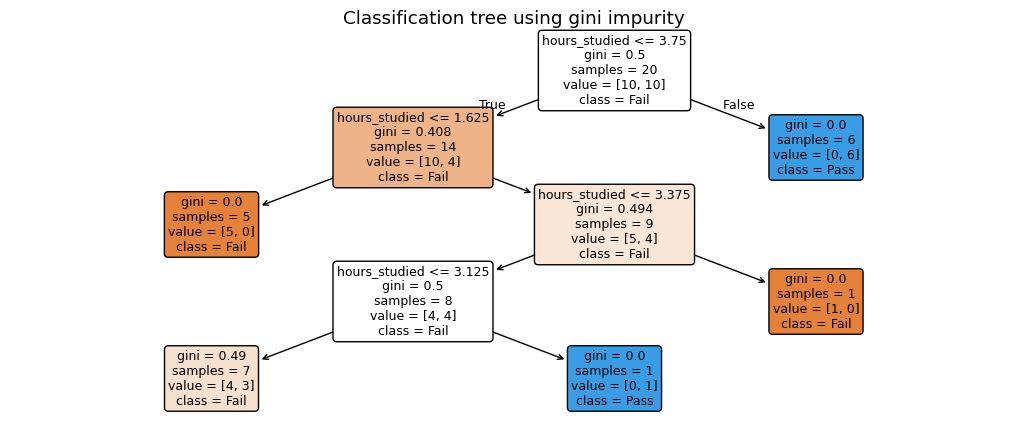

Root Gini: 0.5
Fitted tree leaves: 5


In [14]:
fig, ax = plt.subplots(figsize=(13, 5))
plot_tree(clf_tree, feature_names=['hours_studied'], class_names=['Fail','Pass'],
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title(f'Classification tree using {CLF_CRITERION} impurity'); plt.show()

def gini(labels):
    counts = np.bincount(np.asarray(labels, dtype=int), minlength=2)
    probabilities = counts / counts.sum()
    return 1 - np.sum(probabilities**2)

print('Root Gini:', round(gini(passed), 3))
print('Fitted tree leaves:', clf_tree.get_n_leaves())

## 8 · Transfer the ideas to your original workshop

In [the existing workshop](https://github.com/ProfEspinosaAIML/DecisionTreeRegression_Workshop), the models are introduced with these configurations:

```python
# Regression model: California Housing dataset
reg_tree = DecisionTreeRegressor(max_depth=6, random_state=42)
reg_tree.fit(X_train_c, y_train_c)

# Classification model: Iris dataset
clf_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
clf_tree.fit(X_train_i, y_train_i)
```

The variables above are **defined by the main workshop**, not by this supplementary notebook. In the main notebook, make a prediction, inspect its path, and compare the effect of decreasing the depth to 1 or increasing it substantially. Housing is a numeric prediction; Iris is a category prediction. The algorithmic principle—greedy yes/no splits—is shared; the impurity objective and leaf output differ.

| Dimension | Regression tree | Classification tree |
|---|---|---|
| Output | Numeric value | Category; class probabilities also available |
| Typical split criterion | Squared error | Gini or entropy |
| Typical leaf result | Mean of targets (squared error) | Class proportions and majority class |
| Teaching example | Electricity price by hour | Exam pass/fail by study time |
| Workshop example | California Housing | Iris |
| Workshop starting depth | 6 | 4 |

**Why not replace the main workshop?** The main notebook covers practical datasets, evaluation, and ML pipeline design. This notebook is a concept-first supplement that makes its tree-fitting step intelligible.

## 9 · Mini-challenges and reflection (pause before consulting help)

**Challenge A — arithmetic.** Using the six-row toy dataset, calculate the SSE for threshold `7.0` and explain why the tree might prefer another threshold. Verify with `score_split`.

**Challenge B — algorithm debugging.** Change the homemade tree's `min_samples_leaf` from 1 to 2. What branch or prediction disappears, and why? Is this a bug or a restriction?

**Challenge C — overfitting.** In the electricity experiment, compare depths 1, 3, 6, and `None`. Record training MSE, test MSE, and number of leaves. Which would you investigate further using cross-validation? Why?

**Challenge D — compare classifiers.** In the Wikipedia example, compare `CLF_MAX_DEPTH=1` and `CLF_MAX_DEPTH=4`. Explain one trade-off involving simplicity, fit, and possible overfitting.

**Challenge E — transfer.** In the main workshop, answer: “What does a leaf value represent for housing prices? What does a leaf represent for Iris species?”

**Exit ticket:** Complete these sentences in your own words: “A regression tree chooses a split by ___ . A regression leaf predicts ___ . A classification tree usually measures node purity using ___ . Increasing maximum depth can ___ .”

### Self-check answers (read only after trying)

- A: use `score_split(toy_hour, toy_price, 7.0)`; choose the smallest available **total SSE**, not just the cleanest-looking subgroup.
- B: setting a minimum leaf size forbids splits that would create smaller leaves; preventing tiny leaves is a regularization choice.
- C: training fit generally improves as depth increases, while generalization need not; select complexity using validation/CV, and reserve test data for final assessment.
- D: shallow trees have fewer rules and may underfit; deeper trees fit training points more closely but can become unstable on small datasets.
- E: regression leaves predict a numeric training-target summary; classification leaves represent a distribution of categories and a predicted class.



# Decision Tree Regression Workshop — Exact Challenge Questions, Working, and Answers

**Notebooks:** `notebooks/Decision_Tree_Regression_Algorithm_Coaching.ipynb` (Section 9) and `DecisionTreeRegression_Workshop.ipynb` (Sections 7–8).

The questions below are reproduced from the coaching notebook. Calculations use the notebook's provided data and `random_state=42`.

---

## Challenge 1 (A) — Arithmetic

**Exact question:**  
> Using the six-row toy dataset, calculate the SSE for threshold `7.0` and explain why the tree might prefer another threshold. Verify with `score_split`.

### Working

The six `(hour, price)` observations are:

| Hour | Price |
|---:|---:|
| 2 | 8 |
| 5 | 8 |
| 9 | 12 |
| 12 | 16 |
| 15 | 16 |
| 21 | 8 |

Threshold `7.0` divides the data into:

- **Left (`hour <= 7`)**: `[8, 8]`, mean = `(8 + 8)/2 = 8`
- **Right (`hour > 7`)**: `[12, 16, 16, 8]`, mean = `(12 + 16 + 16 + 8)/4 = 13`

**Sum of Squared Errors (SSE)** = sum of `(actual price − group mean)²`.

Left SSE = `(8−8)² + (8−8)² = 0`

Right SSE = `(12−13)² + (16−13)² + (16−13)² + (8−13)²`  
`= 1 + 9 + 9 + 25 = 44`

**Total SSE = 0 + 44 = 44.**

### Comparison with other thresholds

| Threshold | Total SSE |
|---:|---:|
| 3.5 | 64.00 |
| **7.0** | **44.00** |
| 10.5 | 53.33 |
| 13.5 | 76.00 |
| 18.0 | 64.00 |

**Answer:** A regression tree selects the threshold with the lowest total SSE. Another threshold would be preferred only if it reduced SSE. For this toy dataset, **7.0 is the best available first split**, with total SSE **44**.

**Verification (run after the earlier `score_split` cell):**

```python
print(score_split(toy_hour, toy_price, 7.0))
# Expected: n_left=2, n_right=4, mean_left=8,
# mean_right=13, sse_left=0, sse_right=44, total_sse=44
```

---

## Challenge 2 (B) — Algorithm Debugging

**Exact question:**  
> Change the homemade tree's `min_samples_leaf` from 1 to 2. What branch or prediction disappears, and why? Is this a bug or a restriction?

### Working

The original homemade tree has `max_depth=2`.

**With `min_samples_leaf=1`:**

```text
Is hour <= 7?
├── Yes → predict 8.00
└── No: Is hour <= 18?
    ├── Yes → predict 14.67
    └── No  → predict 8.00
```

The last leaf contains only the observation at hour 21, with price 8.

**With `min_samples_leaf=2`:**

```text
Is hour <= 7?
├── Yes → predict 8.00
└── No: Is hour <= 13.5?
    ├── Yes → predict 14.00
    └── No  → predict 12.00
```

The branch at **18.0 disappears** because it would leave just **one** observation on the right. The new threshold **13.5** keeps two observations in each of the two right-side leaves.

For example, the prediction at **hour 21 changes from 8.00 to 12.00**.

**Answer:** This is **not a bug**. `min_samples_leaf=2` is a restriction that prevents leaves from containing fewer than two observations. It helps control overfitting.

**Verification (run after defining `build_regression_tree`, `print_rules`, and `predict_one`):**

```python
for leaf_size in [1, 2]:
    model = build_regression_tree(
        toy_hour, toy_price, max_depth=2, min_samples_leaf=leaf_size
    )
    print(f"\nmin_samples_leaf = {leaf_size}")
    print_rules(model)
    print("Prediction at hour 21:", predict_one(model, 21))
```

---

## Challenge 3 (C) — Overfitting

**Exact question:**  
> In the electricity experiment, compare depths 1, 3, 6, and `None`. Record training MSE, test MSE, and number of leaves. Which would you investigate further using cross-validation? Why?

### Working

MSE means **Mean Squared Error**, the average squared difference between actual and predicted prices. **Lower MSE is better.**

I trained four models using the electricity dataset from the coaching notebook, its 75%/25% train/test split, `random_state=42`, and `min_samples_leaf=1`.

| `max_depth` | Training MSE | Test MSE | Number of Leaves |
|---|---:|---:|---:|
| 1 | 7.607 | 7.206 | 2 |
| 3 | 1.048 | 1.167 | 8 |
| **6** | **0.031** | **0.284** | **32** |
| None | 0.000 | 0.336 | 52 |

### Interpretation

- **Depth 1** is too simple and underfits: both errors are high.
- **Depth 3** learns more useful patterns and reduces both errors.
- **Depth 6** gives the lowest test MSE of these four models.
- **Depth None** fits the training data perfectly (MSE = 0), but its test MSE increases compared with depth 6, suggesting overfitting.

**Answer:** I would investigate **depth 6** further using cross-validation because it has the lowest held-out test error in this classroom comparison. Cross-validation would help check that its good performance is consistent across different splits. In a real project, hyperparameters should be selected using validation or cross-validation data, leaving a separate test set for final evaluation.

**Verification (run after the electricity train/test split):**

```python
for depth in [1, 3, 6, None]:
    model = DecisionTreeRegressor(
        max_depth=depth, min_samples_leaf=1, random_state=42
    )
    model.fit(X_train, y_train)
    train_mse = mean_squared_error(y_train, model.predict(X_train))
    test_mse = mean_squared_error(y_test, model.predict(X_test))
    print(
        f"depth={str(depth):>4} | "
        f"train MSE={train_mse:.3f} | "
        f"test MSE={test_mse:.3f} | "
        f"leaves={model.get_n_leaves()}"
    )
```

---

## Challenge 4 (D) — Compare Classifiers

**Exact question:**  
> In the Wikipedia example, compare `CLF_MAX_DEPTH=1` and `CLF_MAX_DEPTH=4`. Explain one trade-off involving simplicity, fit, and possible overfitting.

### Working

This example uses 20 students' study hours to predict **pass (1)** or **fail (0)**, using the notebook's `criterion='gini'` and `random_state=42`.

| Maximum Depth | Training Accuracy | Correct Predictions | Number of Leaves |
|---:|---:|---:|---:|
| 1 | 80% | 16/20 | 2 |
| 4 | 85% | 17/20 | 5 |

Accuracy = `(number of correct predictions / total observations) × 100`.

So:

- Depth 1: `(16 / 20) × 100 = 80%`
- Depth 4: `(17 / 20) × 100 = 85%`

**Answer:** With depth 1, the tree has only one decision split and is simple to understand, but it may miss important patterns (**underfitting**). With depth 4, the tree has more branches and fits the training data slightly better. However, a deeper tree can learn noise and **overfit**, especially with only 20 observations. Training accuracy alone cannot tell us which model works better on new students.

**Verification (run after the `study_hours` and `passed` arrays are defined):**

```python
for depth in [1, 4]:
    model = DecisionTreeClassifier(
        max_depth=depth, criterion="gini", random_state=42
    )
    model.fit(study_hours.reshape(-1, 1), passed)
    predictions = model.predict(study_hours.reshape(-1, 1))
    print(
        f"depth={depth} | "
        f"accuracy={accuracy_score(passed, predictions):.0%} | "
        f"leaves={model.get_n_leaves()}"
    )
```

---

## Challenge 5 (E) — Transfer

**Exact question:**  
> In the main workshop, answer: “What does a leaf value represent for housing prices? What does a leaf represent for Iris species?”

### Working and Answer

A **leaf** is the final point of a decision tree, where the model produces a prediction.

- **California Housing (Regression):** A leaf predicts a **numerical house value**. With squared-error loss, it is the **mean target value** of training houses that reached that leaf. In the California Housing dataset, `MedHouseVal` is measured in units of **$100,000**.
- **Iris (Classification):** A leaf represents the **distribution of flower species** among training flowers that reached it. The predicted category is usually the **most common species** (Setosa, Versicolor, or Virginica). The leaf can also provide class probabilities.

**Answer:** A regression leaf predicts a number, while a classification leaf predicts a category using the distribution of classes in that leaf.

---

## Exit Ticket

**Exact question:**  
> Complete these sentences in your own words: “A regression tree chooses a split by ___ . A regression leaf predicts ___ . A classification tree usually measures node purity using ___ . Increasing maximum depth can ___ .”

**Completed answer:**

1. **A regression tree chooses a split by** comparing different feature thresholds and choosing the one that minimizes prediction error, such as SSE.
2. **A regression leaf predicts** the mean target value of training observations in that leaf when using squared-error loss.
3. **A classification tree usually measures node purity using** Gini impurity or entropy.
4. **Increasing maximum depth can** help the tree learn more complex patterns and reduce training error, but it can also cause overfitting.

---

## Main Notebook — Step 8: Reflection and Discussion

### 1. What are the strengths and weaknesses of Decision Trees?

**Answer:** Decision Trees are easy to understand, visualize, and explain. They can model non-linear patterns and do not normally require feature scaling. However, deep trees may overfit, and small data changes can produce different tree structures.

### 2. When are Decision Trees preferable to linear models?

**Answer:** Decision Trees are often useful when relationships are not straight lines and decisions depend on different thresholds or combinations of conditions. They can learn these patterns without manually specifying a non-linear equation.

### 3. How does model depth affect bias and variance?

**Answer:** A shallow tree tends to have **high bias** because it may be too simple and underfit. A deeper tree can have **higher variance** because it becomes more sensitive to the training data and may overfit.

### 4. What challenges arise when integrating models into MLOps pipelines?

**Answer:** We need to track dataset and model versions, record hyperparameters and evaluation metrics, reproduce results, and monitor performance after deployment. Experiment tracking tools such as MLflow can help organize this information.

---

## Where to put the answers

1. In `notebooks/Decision_Tree_Regression_Algorithm_Coaching.ipynb`, go to **Section 9** to review and verify Challenges A–E and the Exit Ticket.
2. In `DecisionTreeRegression_Workshop.ipynb`, go to **Section 7** and replace the five challenge answer placeholders with Challenges 1–5 above, then add the Exit Ticket.
3. Add the four reflection answers under **Section 8** of the main notebook.
4. Run the code cells in both notebooks in order, verify outputs, save, and commit your completed work.
# Decision Tree Regression Workshop — Exact Challenge Questions, Working, and Answers

**Notebooks:** `notebooks/Decision_Tree_Regression_Algorithm_Coaching.ipynb` (Section 9) and `DecisionTreeRegression_Workshop.ipynb` (Sections 7–8).

The questions below are reproduced from the coaching notebook. Calculations use the notebook's provided data and `random_state=42`.

---

## Challenge 1 (A) — Arithmetic

**Exact question:**  
> Using the six-row toy dataset, calculate the SSE for threshold `7.0` and explain why the tree might prefer another threshold. Verify with `score_split`.

### Working

The six `(hour, price)` observations are:

| Hour | Price |
|---:|---:|
| 2 | 8 |
| 5 | 8 |
| 9 | 12 |
| 12 | 16 |
| 15 | 16 |
| 21 | 8 |

Threshold `7.0` divides the data into:

- **Left (`hour <= 7`)**: `[8, 8]`, mean = `(8 + 8)/2 = 8`
- **Right (`hour > 7`)**: `[12, 16, 16, 8]`, mean = `(12 + 16 + 16 + 8)/4 = 13`

**Sum of Squared Errors (SSE)** = sum of `(actual price − group mean)²`.

Left SSE = `(8−8)² + (8−8)² = 0`

Right SSE = `(12−13)² + (16−13)² + (16−13)² + (8−13)²`  
`= 1 + 9 + 9 + 25 = 44`

**Total SSE = 0 + 44 = 44.**

### Comparison with other thresholds

| Threshold | Total SSE |
|---:|---:|
| 3.5 | 64.00 |
| **7.0** | **44.00** |
| 10.5 | 53.33 |
| 13.5 | 76.00 |
| 18.0 | 64.00 |

**Answer:** A regression tree selects the threshold with the lowest total SSE. Another threshold would be preferred only if it reduced SSE. For this toy dataset, **7.0 is the best available first split**, with total SSE **44**.

**Verification (run after the earlier `score_split` cell):**

```python
print(score_split(toy_hour, toy_price, 7.0))
# Expected: n_left=2, n_right=4, mean_left=8,
# mean_right=13, sse_left=0, sse_right=44, total_sse=44
```

---

## Challenge 2 (B) — Algorithm Debugging

**Exact question:**  
> Change the homemade tree's `min_samples_leaf` from 1 to 2. What branch or prediction disappears, and why? Is this a bug or a restriction?

### Working

The original homemade tree has `max_depth=2`.

**With `min_samples_leaf=1`:**

```text
Is hour <= 7?
├── Yes → predict 8.00
└── No: Is hour <= 18?
    ├── Yes → predict 14.67
    └── No  → predict 8.00
```

The last leaf contains only the observation at hour 21, with price 8.

**With `min_samples_leaf=2`:**

```text
Is hour <= 7?
├── Yes → predict 8.00
└── No: Is hour <= 13.5?
    ├── Yes → predict 14.00
    └── No  → predict 12.00
```

The branch at **18.0 disappears** because it would leave just **one** observation on the right. The new threshold **13.5** keeps two observations in each of the two right-side leaves.

For example, the prediction at **hour 21 changes from 8.00 to 12.00**.

**Answer:** This is **not a bug**. `min_samples_leaf=2` is a restriction that prevents leaves from containing fewer than two observations. It helps control overfitting.

**Verification (run after defining `build_regression_tree`, `print_rules`, and `predict_one`):**

```python
for leaf_size in [1, 2]:
    model = build_regression_tree(
        toy_hour, toy_price, max_depth=2, min_samples_leaf=leaf_size
    )
    print(f"\nmin_samples_leaf = {leaf_size}")
    print_rules(model)
    print("Prediction at hour 21:", predict_one(model, 21))
```

---

## Challenge 3 (C) — Overfitting

**Exact question:**  
> In the electricity experiment, compare depths 1, 3, 6, and `None`. Record training MSE, test MSE, and number of leaves. Which would you investigate further using cross-validation? Why?

### Working

MSE means **Mean Squared Error**, the average squared difference between actual and predicted prices. **Lower MSE is better.**

I trained four models using the electricity dataset from the coaching notebook, its 75%/25% train/test split, `random_state=42`, and `min_samples_leaf=1`.

| `max_depth` | Training MSE | Test MSE | Number of Leaves |
|---|---:|---:|---:|
| 1 | 7.607 | 7.206 | 2 |
| 3 | 1.048 | 1.167 | 8 |
| **6** | **0.031** | **0.284** | **32** |
| None | 0.000 | 0.336 | 52 |

### Interpretation

- **Depth 1** is too simple and underfits: both errors are high.
- **Depth 3** learns more useful patterns and reduces both errors.
- **Depth 6** gives the lowest test MSE of these four models.
- **Depth None** fits the training data perfectly (MSE = 0), but its test MSE increases compared with depth 6, suggesting overfitting.

**Answer:** I would investigate **depth 6** further using cross-validation because it has the lowest held-out test error in this classroom comparison. Cross-validation would help check that its good performance is consistent across different splits. In a real project, hyperparameters should be selected using validation or cross-validation data, leaving a separate test set for final evaluation.

**Verification (run after the electricity train/test split):**

```python
for depth in [1, 3, 6, None]:
    model = DecisionTreeRegressor(
        max_depth=depth, min_samples_leaf=1, random_state=42
    )
    model.fit(X_train, y_train)
    train_mse = mean_squared_error(y_train, model.predict(X_train))
    test_mse = mean_squared_error(y_test, model.predict(X_test))
    print(
        f"depth={str(depth):>4} | "
        f"train MSE={train_mse:.3f} | "
        f"test MSE={test_mse:.3f} | "
        f"leaves={model.get_n_leaves()}"
    )
```

---

## Challenge 4 (D) — Compare Classifiers

**Exact question:**  
> In the Wikipedia example, compare `CLF_MAX_DEPTH=1` and `CLF_MAX_DEPTH=4`. Explain one trade-off involving simplicity, fit, and possible overfitting.

### Working

This example uses 20 students' study hours to predict **pass (1)** or **fail (0)**, using the notebook's `criterion='gini'` and `random_state=42`.

| Maximum Depth | Training Accuracy | Correct Predictions | Number of Leaves |
|---:|---:|---:|---:|
| 1 | 80% | 16/20 | 2 |
| 4 | 85% | 17/20 | 5 |

Accuracy = `(number of correct predictions / total observations) × 100`.

So:

- Depth 1: `(16 / 20) × 100 = 80%`
- Depth 4: `(17 / 20) × 100 = 85%`

**Answer:** With depth 1, the tree has only one decision split and is simple to understand, but it may miss important patterns (**underfitting**). With depth 4, the tree has more branches and fits the training data slightly better. However, a deeper tree can learn noise and **overfit**, especially with only 20 observations. Training accuracy alone cannot tell us which model works better on new students.

**Verification (run after the `study_hours` and `passed` arrays are defined):**

```python
for depth in [1, 4]:
    model = DecisionTreeClassifier(
        max_depth=depth, criterion="gini", random_state=42
    )
    model.fit(study_hours.reshape(-1, 1), passed)
    predictions = model.predict(study_hours.reshape(-1, 1))
    print(
        f"depth={depth} | "
        f"accuracy={accuracy_score(passed, predictions):.0%} | "
        f"leaves={model.get_n_leaves()}"
    )
```

---

## Challenge 5 (E) — Transfer

**Exact question:**  
> In the main workshop, answer: “What does a leaf value represent for housing prices? What does a leaf represent for Iris species?”

### Working and Answer

A **leaf** is the final point of a decision tree, where the model produces a prediction.

- **California Housing (Regression):** A leaf predicts a **numerical house value**. With squared-error loss, it is the **mean target value** of training houses that reached that leaf. In the California Housing dataset, `MedHouseVal` is measured in units of **$100,000**.
- **Iris (Classification):** A leaf represents the **distribution of flower species** among training flowers that reached it. The predicted category is usually the **most common species** (Setosa, Versicolor, or Virginica). The leaf can also provide class probabilities.

**Answer:** A regression leaf predicts a number, while a classification leaf predicts a category using the distribution of classes in that leaf.

---

## Exit Ticket

**Exact question:**  
> Complete these sentences in your own words: “A regression tree chooses a split by ___ . A regression leaf predicts ___ . A classification tree usually measures node purity using ___ . Increasing maximum depth can ___ .”

**Completed answer:**

1. **A regression tree chooses a split by** comparing different feature thresholds and choosing the one that minimizes prediction error, such as SSE.
2. **A regression leaf predicts** the mean target value of training observations in that leaf when using squared-error loss.
3. **A classification tree usually measures node purity using** Gini impurity or entropy.
4. **Increasing maximum depth can** help the tree learn more complex patterns and reduce training error, but it can also cause overfitting.

---

## Main Notebook — Step 8: Reflection and Discussion

### 1. What are the strengths and weaknesses of Decision Trees?

**Answer:** Decision Trees are easy to understand, visualize, and explain. They can model non-linear patterns and do not normally require feature scaling. However, deep trees may overfit, and small data changes can produce different tree structures.

### 2. When are Decision Trees preferable to linear models?

**Answer:** Decision Trees are often useful when relationships are not straight lines and decisions depend on different thresholds or combinations of conditions. They can learn these patterns without manually specifying a non-linear equation.

### 3. How does model depth affect bias and variance?

**Answer:** A shallow tree tends to have **high bias** because it may be too simple and underfit. A deeper tree can have **higher variance** because it becomes more sensitive to the training data and may overfit.

### 4. What challenges arise when integrating models into MLOps pipelines?

**Answer:** We need to track dataset and model versions, record hyperparameters and evaluation metrics, reproduce results, and monitor performance after deployment. Experiment tracking tools such as MLflow can help organize this information.

---

## Where to put the answers

1. In `notebooks/Decision_Tree_Regression_Algorithm_Coaching.ipynb`, go to **Section 9** to review and verify Challenges A–E and the Exit Ticket.
2. In `DecisionTreeRegression_Workshop.ipynb`, go to **Section 7** and replace the five challenge answer placeholders with Challenges 1–5 above, then add the Exit Ticket.
3. Add the four reflection answers under **Section 8** of the main notebook.
4. Run the code cells in both notebooks in order, verify outputs, save, and commit your completed work.


In [15]:
# Optional verification checkpoint: students can use this AFTER Challenge A.
print('Threshold 7.0:', score_split(toy_hour, toy_price, 7.0))
print('Threshold 10.5:', score_split(toy_hour, toy_price, 10.5))

# Automated mathematical sanity checks.
assert np.allclose(sk_toy.predict(toy_hour.reshape(-1, 1)),
                   predict_many(toy_tree, toy_hour))
assert np.isclose(gini(np.array([0, 0, 1, 1])), .5)
assert reg_tree.get_depth() <= REG_MAX_DEPTH if REG_MAX_DEPTH is not None else True
print('Sanity checks passed.')

Threshold 7.0: {'threshold': 7.0, 'n_left': 2, 'n_right': 4, 'mean_left': np.float64(8.0), 'mean_right': np.float64(13.0), 'sse_left': np.float64(0.0), 'sse_right': np.float64(44.0), 'total_sse': np.float64(44.0)}
Threshold 10.5: {'threshold': 10.5, 'n_left': 3, 'n_right': 3, 'mean_left': np.float64(9.333333333333334), 'mean_right': np.float64(13.333333333333334), 'sse_left': np.float64(10.666666666666668), 'sse_right': np.float64(42.666666666666664), 'total_sse': np.float64(53.33333333333333)}
Sanity checks passed.


---
**References and distinctions**

1. Uploaded `ParametricNon-Parametric_Regression_Lab.html`, Decision Tree family and Ontario time-of-use example: the synthetic tier values, noise magnitude, one-dimensional story, and model family interpretation are adapted from this source.
2. [StatQuest, *Regression Trees, Clearly Explained!!!*](https://www.youtube.com/watch?v=g9c66TUylZ4): inspiration for the teach-by-splitting explanatory progression; all notebook graphics are newly generated.
3. [Wikipedia, *Logistic regression — Example*](https://en.wikipedia.org/wiki/Logistic_regression#Example): source of the 20 observed study-hours/pass-fail pairs.
4. [DecisionTreeRegression_Workshop](https://github.com/ProfEspinosaAIML/DecisionTreeRegression_Workshop): supplementary alignment with California Housing and Iris exercises.
5. [scikit-learn tree documentation](https://scikit-learn.org/stable/modules/tree.html): algorithm reference, supported criteria, and stopping settings.

*Use of artificial electricity data is explicitly for teaching threshold behavior, not for making electricity billing decisions.*